# MO-IT128 - Data Mining Principles - MILESTONE 1
# FinMark Corporation
## Project Data Preparation, Feature Engineering, and Exploratory Data Analysis

This notebook consolidates the full Milestone 1 workflow in a single file:

1. Load raw datasets  
2. Apply minimal pre-merge harmonization (only what is required to join consistently)  
3. Create a **customer-level feedback summary** to define a stable merge grain  
4. Merge transactions and customer data **before** full cleaning  
5. Clean and standardize the merged dataset  
6. Clean the product offering dataset as a separate, submission-ready output  
7. Perform feature engineering (including **income grouping** using quartiles/percentiles derived from transaction amounts)  
8. Conduct EDA and visualizations to understand the merged dataset and engineered outputs  
9. Export cleaned and engineered datasets


## 0) Setup

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 250)
pd.set_option("display.width", 140)
pd.options.display.float_format = "{:,.2f}".format


## 1) Load raw datasets

**Datasets**
- **Transactions:** customer activity records (dates, types, amounts)
- **Customer Feedback:** satisfaction and recommendation signals (multiple rows may exist per customer)
- **Product Offering:** product catalog/context (no reliable join key provided for transaction linkage)

The merge-first workflow depends on consistently formatted join keys and correct parsing of timestamp fields.


In [41]:
# File loading assumes the CSV files are in the SAME folder as this notebook.
# This keeps the notebook portable across machines and submission folders.

import pandas as pd
from pathlib import Path

# Resolve paths relative to the notebook location when possible
# (Fallback to current working directory if __file__/notebook path is unavailable)
data_dir = Path.cwd()

txn_file  = data_dir / "Transaction_Data.csv"
fb_file   = data_dir / "Customer_Feedback_Data.csv"
prod_file = data_dir / "Product_Offering_Data.csv"

transactions_raw = pd.read_csv(txn_file)
feedback_raw     = pd.read_csv(fb_file)
products_raw     = pd.read_csv(prod_file)

print("Transactions:", transactions_raw.shape)
print("Feedback:", feedback_raw.shape)
print("Products:", products_raw.shape)

display(transactions_raw.head())
display(feedback_raw.head())
display(products_raw.head())


Transactions: (5050, 5)
Feedback: (5050, 4)
Products: (15, 6)


,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Amount,Transaction_Type
0,1,393,2023-01-01 00:00:00,"3,472.00",Purchase
1,2,826,2023-01-01 01:00:00,NaN,Bill Payment
2,3,916,2023-01-01 02:00:00,10.00,Purchase
3,4,109,2023-01-01 03:00:00,72.00,Investment
4,5,889,2023-01-01 04:00:00,"1,793.00",Investment


,Customer_ID,Satisfaction_Score,Feedback_Comments,Likelihood_to_Recommend
0,1,10.00,Very satisfied,9
1,2,3.00,Very satisfied,3
2,3,10.00,Very satisfied,1
3,4,7.00,Needs improvement,4
4,5,8.00,Unsatisfactory,7


,Product_ID,Product_Name,Product_Type,Risk_Level,Target_Age_Group,Target_Income_Group
0,1,Platinum Credit Card,Credit Card,Medium,NaN,Medium
1,2,Gold Savings Account,Savings Account,Low,NaN,Low
2,3,High-Yield Investment Account,Investment,High,NaN,High
3,4,Mortgage Loan,Loan,Medium,NaN,High
4,5,Auto Loan,Loan,Medium,NaN,Medium


## 2) Pre-merge harmonization (minimal)

Only minimal transformations are performed at this stage to avoid repeated processing:
- `Customer_ID` is standardized as trimmed text
- `Transaction_Date` is parsed to datetime (errors coerced to missing)
- Feedback numeric fields are coerced to numeric types for reliable aggregation


In [42]:
def norm_id(s):
    if pd.isna(s):
        return s
    return str(s).strip()

for df in (transactions_raw, feedback_raw, products_raw):
    if "Customer_ID" in df.columns:
        df["Customer_ID"] = df["Customer_ID"].apply(norm_id)

if "Transaction_Date" in transactions_raw.columns:
    transactions_raw["Transaction_Date"] = pd.to_datetime(transactions_raw["Transaction_Date"], errors="coerce")

for c in ["Satisfaction_Score", "Likelihood_to_Recommend"]:
    if c in feedback_raw.columns:
        feedback_raw[c] = pd.to_numeric(feedback_raw[c], errors="coerce")

if "Feedback_Comments" in feedback_raw.columns:
    feedback_raw["Feedback_Comments"] = feedback_raw["Feedback_Comments"].astype(str).replace("nan", np.nan).str.strip()

display(transactions_raw.head())


,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Amount,Transaction_Type
0,1,393,2023-01-01 00:00:00,"3,472.00",Purchase
1,2,826,2023-01-01 01:00:00,NaN,Bill Payment
2,3,916,2023-01-01 02:00:00,10.00,Purchase
3,4,109,2023-01-01 03:00:00,72.00,Investment
4,5,889,2023-01-01 04:00:00,"1,793.00",Investment


## 3) Define customer-level feedback summary (stable merge grain)

Feedback data can contain multiple entries per customer. A direct merge between transactions and raw feedback rows can inflate row counts and distort downstream calculations.

To maintain a stable, model-friendly grain, feedback is summarized to **one row per customer**:
- count of feedback entries  
- mean and standard deviation for satisfaction and likelihood-to-recommend  
- most frequent feedback comment label (mode) when available  


In [43]:
fb = feedback_raw.copy()

feedback_customer_summary = (
    fb.groupby("Customer_ID", dropna=False)
      .agg(
          feedback_count=("Customer_ID", "size"),
          satisfaction_mean=("Satisfaction_Score", "mean"),
          satisfaction_std=("Satisfaction_Score", "std"),
          ltr_mean=("Likelihood_to_Recommend", "mean"),
          ltr_std=("Likelihood_to_Recommend", "std"),
      )
      .reset_index()
)

if "Feedback_Comments" in fb.columns:
    top_comment = (
        fb.dropna(subset=["Feedback_Comments"])
          .groupby("Customer_ID")["Feedback_Comments"]
          .agg(lambda s: s.value_counts().index[0] if len(s) else np.nan)
          .reset_index(name="top_comment")
    )
    feedback_customer_summary = feedback_customer_summary.merge(top_comment, on="Customer_ID", how="left")
else:
    feedback_customer_summary["top_comment"] = np.nan

display(feedback_customer_summary.head())
print("Customer-level feedback rows:", feedback_customer_summary.shape[0])


,Customer_ID,feedback_count,satisfaction_mean,satisfaction_std,ltr_mean,ltr_std,top_comment
0,1,2,8.50,2.12,9.00,0.00,Very satisfied
1,10,5,5.40,2.19,3.00,2.12,Good service
2,100,2,8.00,1.41,7.50,3.54,Good service
3,1000,4,4.25,1.71,8.00,2.16,Unsatisfactory
4,101,7,5.00,3.92,7.14,3.29,Good service


Customer-level feedback rows: 1000


## 4) Merge first (transactions + customer summary)

The merged dataset becomes the single source of truth for cleaning, feature engineering, and EDA.


In [44]:
merged_raw = transactions_raw.merge(feedback_customer_summary, on="Customer_ID", how="left")
print("Merged (raw) shape:", merged_raw.shape)
display(merged_raw.head())


Merged (raw) shape: (5050, 11)


,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Amount,Transaction_Type,feedback_count,satisfaction_mean,satisfaction_std,ltr_mean,ltr_std,top_comment
0,1,393,2023-01-01 00:00:00,"3,472.00",Purchase,1,1.00,NaN,3.00,NaN,Excellent
1,2,826,2023-01-01 01:00:00,NaN,Bill Payment,6,6.20,3.27,5.50,2.88,Needs improvement
2,3,916,2023-01-01 02:00:00,10.00,Purchase,7,2.71,2.06,5.00,3.21,Needs improvement
3,4,109,2023-01-01 03:00:00,72.00,Investment,3,3.00,1.00,7.00,2.00,Good service
4,5,889,2023-01-01 04:00:00,"1,793.00",Investment,5,5.00,3.08,5.60,2.70,Good service


## 5) Data quality assessment (merged)

This step documents baseline data quality:
- missing values overview  
- duplicates (using transaction identifiers when available)  


In [45]:
merged = merged_raw.copy()

display(merged.isna().sum().sort_values(ascending=False).head(15))

txn_key_cols = [c for c in ["Transaction_ID","Customer_ID","Transaction_Date","Transaction_Type","Transaction_Amount"] if c in merged.columns]
print("Duplicate-check keys:", txn_key_cols)

dup_count = merged.duplicated(subset=txn_key_cols).sum() if txn_key_cols else merged.duplicated().sum()
print("Duplicates detected:", int(dup_count))


satisfaction_std      116
Transaction_Amount    100
ltr_std                85
Transaction_ID          0
Customer_ID             0
Transaction_Date        0
Transaction_Type        0
feedback_count          0
satisfaction_mean       0
ltr_mean                0
top_comment             0
dtype: int64

Duplicate-check keys: ['Transaction_ID', 'Customer_ID', 'Transaction_Date', 'Transaction_Type', 'Transaction_Amount']
Duplicates detected: 50


## 6) Cleaning and standardization (merged)

**Decisions applied**
- **Duplicates:** removed using transaction-level key fields (when available).
- **Missing transaction amounts:** imputed using median-per-transaction-type (fallback to global median).
- **Category labels:** `Transaction_Type` trimmed and standardized; missing values set to `Unknown`.
- **Outliers:** IQR-based capping applied to reduce distortion while retaining records.
- **Presentation:** numeric fields rounded to 2 decimals for clean exported outputs.


In [46]:
# 6.1 Remove duplicates
if txn_key_cols:
    merged = merged.drop_duplicates(subset=txn_key_cols, keep="first")
else:
    merged = merged.drop_duplicates(keep="first")

# 6.2 Transaction amount cleanup + missing handling
if "Transaction_Amount" in merged.columns:
    merged["Transaction_Amount"] = pd.to_numeric(merged["Transaction_Amount"], errors="coerce")
    merged["amount_was_missing"] = merged["Transaction_Amount"].isna().astype(int)

    if "Transaction_Type" in merged.columns:
        med_by_type = merged.groupby("Transaction_Type")["Transaction_Amount"].transform("median")
        merged["Transaction_Amount"] = merged["Transaction_Amount"].fillna(med_by_type).fillna(merged["Transaction_Amount"].median())
    else:
        merged["Transaction_Amount"] = merged["Transaction_Amount"].fillna(merged["Transaction_Amount"].median())

# 6.3 Normalize Transaction_Type formatting
if "Transaction_Type" in merged.columns:
    merged["Transaction_Type"] = merged["Transaction_Type"].astype(str).str.strip()
    merged.loc[merged["Transaction_Type"].str.lower().isin(["nan","none",""]),"Transaction_Type"] = np.nan
    merged["Transaction_Type"] = merged["Transaction_Type"].fillna("Unknown")

# 6.4 Outlier handling (IQR cap)
if "Transaction_Amount" in merged.columns:
    q1 = merged["Transaction_Amount"].quantile(0.25)
    q3 = merged["Transaction_Amount"].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5*iqr
    upper = q3 + 1.5*iqr

    merged["amount_outlier_flag"] = ((merged["Transaction_Amount"] < lower) | (merged["Transaction_Amount"] > upper)).astype(int)
    merged["Transaction_Amount"] = merged["Transaction_Amount"].clip(lower=lower, upper=upper)

# 6.5 Clean-looking numeric output
num_cols = merged.select_dtypes(include=[np.number]).columns
merged[num_cols] = merged[num_cols].round(2)

# 6.6 Date parts for EDA context
if "Transaction_Date" in merged.columns:
    merged["Transaction_Year"] = merged["Transaction_Date"].dt.year.astype("Int64")
    merged["Transaction_Month"] = merged["Transaction_Date"].dt.month.astype("Int64")

print("Merged (cleaned) shape:", merged.shape)
display(merged.head())


Merged (cleaned) shape: (5000, 15)


,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Amount,Transaction_Type,feedback_count,satisfaction_mean,satisfaction_std,ltr_mean,ltr_std,top_comment,amount_was_missing,amount_outlier_flag,Transaction_Year,Transaction_Month
0,1,393,2023-01-01 00:00:00,"3,472.00",Purchase,1,1.00,NaN,3.00,NaN,Excellent,0,0,2023,1
1,2,826,2023-01-01 01:00:00,"2,485.00",Bill Payment,6,6.20,3.27,5.50,2.88,Needs improvement,1,0,2023,1
2,3,916,2023-01-01 02:00:00,10.00,Purchase,7,2.71,2.06,5.00,3.21,Needs improvement,0,0,2023,1
3,4,109,2023-01-01 03:00:00,72.00,Investment,3,3.00,1.00,7.00,2.00,Good service,0,0,2023,1
4,5,889,2023-01-01 04:00:00,"1,793.00",Investment,5,5.00,3.08,5.60,2.70,Good service,0,0,2023,1


## 7) Product offering cleanup (separate output)

The product dataset is cleaned as a separate output because the provided tables do not include a reliable key for transaction-level joins.


In [47]:
import re

products = products_raw.copy()

for c in products.columns:
    if products[c].dtype == "object":
        products[c] = products[c].astype(str).replace("nan", np.nan).str.strip()

for c in products.columns:
    if re.search(r"(price|cost|amount|revenue|margin)", c, re.IGNORECASE):
        products[c] = pd.to_numeric(products[c], errors="coerce")

products = products.drop_duplicates()

pnum = products.select_dtypes(include=[np.number]).columns
products[pnum] = products[pnum].round(2)

print("Products (cleaned) shape:", products.shape)
display(products.head())


Products (cleaned) shape: (10, 6)


,Product_ID,Product_Name,Product_Type,Risk_Level,Target_Age_Group,Target_Income_Group
0,1,Platinum Credit Card,Credit Card,Medium,NaN,Medium
1,2,Gold Savings Account,Savings Account,Low,NaN,Low
2,3,High-Yield Investment Account,Investment,High,NaN,High
3,4,Mortgage Loan,Loan,Medium,NaN,High
4,5,Auto Loan,Loan,Medium,NaN,Medium


## 8) Feature engineering (post-clean)

This section creates new variables that are useful for later modeling and for interpretability during EDA.

**Included feature groups**
- **Temporal features** from `Transaction_Date` (week/year, time-of-day)
- **Spend trends** (daily and weekly totals grouped correctly)
- **Feedback sentiment encoding** using the most common feedback category
- **Income grouping** derived from transaction-derived spend metrics using quartiles (Low / Medium / High)


In [48]:
df = merged.copy()

# 8.1 Temporal feature extraction
if "Transaction_Date" in df.columns:
    df["Transaction_Day"] = df["Transaction_Date"].dt.date
    df["Transaction_Week"] = df["Transaction_Date"].dt.isocalendar().week.astype("Int64")
    df["Transaction_ISOYear"] = df["Transaction_Date"].dt.isocalendar().year.astype("Int64")
    df["Transaction_DayOfWeek"] = df["Transaction_Date"].dt.day_name()
    df["Transaction_Hour"] = df["Transaction_Date"].dt.hour.astype("Int64")

    def time_of_day_bucket(h):
        if pd.isna(h): return "Unknown"
        h=int(h)
        if 5 <= h <= 11: return "Morning"
        if 12 <= h <= 16: return "Afternoon"
        if 17 <= h <= 20: return "Evening"
        return "Night"

    df["Transaction_TimeOfDay"] = df["Transaction_Hour"].apply(time_of_day_bucket)

# 8.2 Feedback sentiment encoding (from top_comment)
sentiment_map = {
    "Excellent": 1.0,
    "Very Satisfied": 1.0,
    "Good Service": 0.5,
    "Needs Improvement": -0.5,
    "Unsatisfactory": -1.0,
}
df["top_comment_sentiment"] = df.get("top_comment", pd.Series([np.nan]*len(df))).map(sentiment_map).fillna(0.0)

# 8.3 Customer-level spend proxy (transaction-derived)
customer_spend = df.groupby("Customer_ID", as_index=False).agg(
    total_spend=("Transaction_Amount", "sum"),
    avg_spend=("Transaction_Amount", "mean"),
    txn_count=("Transaction_ID", "size") if "Transaction_ID" in df.columns else ("Transaction_Amount", "size"),
)

p_low = 0.20  # 20th percentile
p_high = 0.75 # 75th percentile
p_low_spend = customer_spend["total_spend"].quantile(p_low)
p_high_spend = customer_spend["total_spend"].quantile(p_high)
def income_group(x):
    if pd.isna(x): return "Medium"
    if x <= p_low_spend: return "Low"
    if x >= p_high_spend: return "High"
    return "Medium"

customer_spend["Income_Group"] = customer_spend["total_spend"].apply(income_group)

# Attach Income_Group back to transactions
df = df.merge(customer_spend[["Customer_ID","Income_Group"]], on="Customer_ID", how="left")

# 8.4 Daily/Weekly spend trends (grouped correctly)
daily = df.groupby(["Customer_ID","Transaction_Day"], as_index=False).agg(Daily_Spend_Trend=("Transaction_Amount","sum"))
df = df.merge(daily, on=["Customer_ID","Transaction_Day"], how="left")

weekly = df.groupby(["Customer_ID","Transaction_ISOYear","Transaction_Week"], as_index=False).agg(Weekly_Spend_Trend=("Transaction_Amount","sum"))
df = df.merge(weekly, on=["Customer_ID","Transaction_ISOYear","Transaction_Week"], how="left")

# Presentation cleanup
num_cols = df.select_dtypes(include=[np.number]).columns
df[num_cols] = df[num_cols].round(2)

display(df.head())
print("Income group cutoffs (total_spend, percentile-based tiers):")
print("P33 (33%):", round(p_low_spend,2), "| P67 (67%):", round(p_high_spend,2))


,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Amount,Transaction_Type,feedback_count,satisfaction_mean,satisfaction_std,ltr_mean,ltr_std,top_comment,amount_was_missing,amount_outlier_flag,Transaction_Year,Transaction_Month,Transaction_Day,Transaction_Week,Transaction_ISOYear,Transaction_DayOfWeek,Transaction_Hour,Transaction_TimeOfDay,top_comment_sentiment,Income_Group,Daily_Spend_Trend,Weekly_Spend_Trend
0,1,393,2023-01-01 00:00:00,"3,472.00",Purchase,1,1.00,NaN,3.00,NaN,Excellent,0,0,2023,1,2023-01-01,52,2022,Sunday,0,Night,1.00,High,"3,472.00","3,472.00"
1,2,826,2023-01-01 01:00:00,"2,485.00",Bill Payment,6,6.20,3.27,5.50,2.88,Needs improvement,1,0,2023,1,2023-01-01,52,2022,Sunday,1,Night,0.00,Medium,"2,485.00","2,485.00"
2,3,916,2023-01-01 02:00:00,10.00,Purchase,7,2.71,2.06,5.00,3.21,Needs improvement,0,0,2023,1,2023-01-01,52,2022,Sunday,2,Night,0.00,High,"1,062.00","1,062.00"
3,4,109,2023-01-01 03:00:00,72.00,Investment,3,3.00,1.00,7.00,2.00,Good service,0,0,2023,1,2023-01-01,52,2022,Sunday,3,Night,0.00,Medium,72.00,72.00
4,5,889,2023-01-01 04:00:00,"1,793.00",Investment,5,5.00,3.08,5.60,2.70,Good service,0,0,2023,1,2023-01-01,52,2022,Sunday,4,Night,0.00,Low,"1,793.00","1,793.00"


Income group cutoffs (total_spend, percentile-based tiers):
P33 (33%): 6860.2 | P67 (67%): 16531.0


## 9) Customer-level feature table (segmentation-ready)

This table aggregates transaction-level behavior into one row per customer.  
It includes spend intensity, timing patterns, transaction type mix, and feedback summary signals.


In [49]:
from sklearn.preprocessing import StandardScaler

# Recency/tenure
overall_last = df["Transaction_Date"].max()
tenure = df.groupby("Customer_ID").agg(
    first_txn=("Transaction_Date", "min"),
    last_txn=("Transaction_Date", "max"),
    active_days=("Transaction_Day", "nunique"),
).reset_index()
tenure["tenure_days"] = (tenure["last_txn"] - tenure["first_txn"]).dt.days.clip(lower=0)
tenure["recency_days"] = (overall_last - tenure["last_txn"]).dt.days.clip(lower=0)

# Timing ratios
tmp = df.copy()
tmp["dow"] = tmp["Transaction_Date"].dt.dayofweek
tmp["is_weekend"] = tmp["dow"].isin([5,6]).astype(int)
tmp["is_business_hours"] = tmp["Transaction_Hour"].between(9,16).astype(int)

timing = tmp.groupby("Customer_ID").agg(
    pct_weekend_txn=("is_weekend","mean"),
    pct_business_hours_txn=("is_business_hours","mean"),
    avg_txn_hour=("Transaction_Hour","mean"),
).reset_index()

# Transaction type distribution
type_dist = df.pivot_table(index="Customer_ID", columns="Transaction_Type", values="Transaction_Amount", aggfunc="size", fill_value=0).reset_index()
type_cols = [c for c in type_dist.columns if c!="Customer_ID"]
type_dist = type_dist.rename(columns={c: f"count_type_{str(c).lower().replace(' ','_')}" for c in type_cols})

# Time-of-day proportions
tod = pd.get_dummies(df[["Customer_ID","Transaction_TimeOfDay"]], columns=["Transaction_TimeOfDay"])
tod = tod.groupby("Customer_ID").mean().reset_index()
tod = tod.rename(columns={c: c.replace("Transaction_TimeOfDay_", "pct_tod_") for c in tod.columns if c.startswith("Transaction_TimeOfDay_")})

# Risk proxy on transaction amount
q25 = df["Transaction_Amount"].quantile(0.25)
q75 = df["Transaction_Amount"].quantile(0.75)
df["risk_proxy"] = np.where(df["Transaction_Amount"]>=q75, "High", np.where(df["Transaction_Amount"]<=q25, "Low", "Medium"))
risk = df.groupby("Customer_ID").agg(
    high_risk_txn_count=("risk_proxy", lambda s: int((s=="High").sum())),
    pct_high_risk_txn=("risk_proxy", lambda s: float((s=="High").mean())),
).reset_index()

# Assemble customer features
customer_features = (
    customer_spend.merge(tenure[["Customer_ID","active_days","tenure_days","recency_days"]], on="Customer_ID", how="left")
                 .merge(timing, on="Customer_ID", how="left")
                 .merge(type_dist, on="Customer_ID", how="left")
                 .merge(tod, on="Customer_ID", how="left")
                 .merge(risk, on="Customer_ID", how="left")
                 .merge(feedback_customer_summary, on="Customer_ID", how="left")
)

# Fill missing values
for col in customer_features.columns:
    if col == "Customer_ID":
        continue
    if customer_features[col].dtype.kind in "biufc":
        customer_features[col] = customer_features[col].fillna(0)
    else:
        customer_features[col] = customer_features[col].fillna("Unknown")

customer_features = customer_features.round(2)
display(customer_features.head())

# Scaled version for clustering
numeric_cols = [c for c in customer_features.columns if c not in ["Customer_ID","Income_Group","top_comment"] and customer_features[c].dtype.kind in "biufc"]
scaler = StandardScaler()
scaled = scaler.fit_transform(customer_features[numeric_cols]) if numeric_cols else np.empty((len(customer_features),0))
customer_features_scaled = pd.DataFrame(scaled, columns=numeric_cols)
customer_features_scaled.insert(0, "Customer_ID", customer_features["Customer_ID"].values)

print("Customer features shape:", customer_features.shape)


,Customer_ID,total_spend,avg_spend,txn_count,Income_Group,active_days,tenure_days,recency_days,pct_weekend_txn,pct_business_hours_txn,avg_txn_hour,count_type_bill_payment,count_type_investment,count_type_loan_payment,count_type_purchase,pct_tod_Afternoon,pct_tod_Evening,pct_tod_Morning,pct_tod_Night,high_risk_txn_count,pct_high_risk_txn,feedback_count,satisfaction_mean,satisfaction_std,ltr_mean,ltr_std,top_comment
0,1,"16,836.00","2,806.00",6,High,6,180,26,0.17,0.17,6.83,3,1,1,1,0.17,0.17,0.00,0.67,3,0.50,2,8.50,2.12,9.00,0.00,Very satisfied
1,10,"15,682.00","2,613.67",6,Medium,6,126,5,0.50,0.67,13.50,3,1,0,2,0.50,0.17,0.33,0.00,2,0.33,5,5.40,2.19,3.00,2.12,Good service
2,100,"5,850.00","1,462.50",4,Low,4,106,8,0.00,0.25,9.50,1,1,1,1,0.25,0.00,0.00,0.75,0,0.00,2,8.00,1.41,7.50,3.54,Good service
3,1000,"9,652.00","1,608.67",6,Medium,6,120,37,0.17,0.17,12.50,0,2,3,1,0.00,0.50,0.50,0.00,0,0.00,4,4.25,1.71,8.00,2.16,Unsatisfactory
4,101,"1,552.00","1,552.00",1,Low,1,0,139,1.00,0.00,6.00,0,1,0,0,0.00,0.00,1.00,0.00,0,0.00,7,5.00,3.92,7.14,3.29,Good service


Customer features shape: (993, 27)


## 10) EDA and visualizations

The following visual checks are included:
- Transaction amount distribution
- Transaction type mix
- Income group distribution (customer-level)
- Satisfaction vs income group (customer-level)
- Correlation scan for numeric features



EDA and VISUALIZATIONS
--------------------------------------------------------------------------------

10.1 Transaction-Level Overview
--------------------------------------------------------------------------------


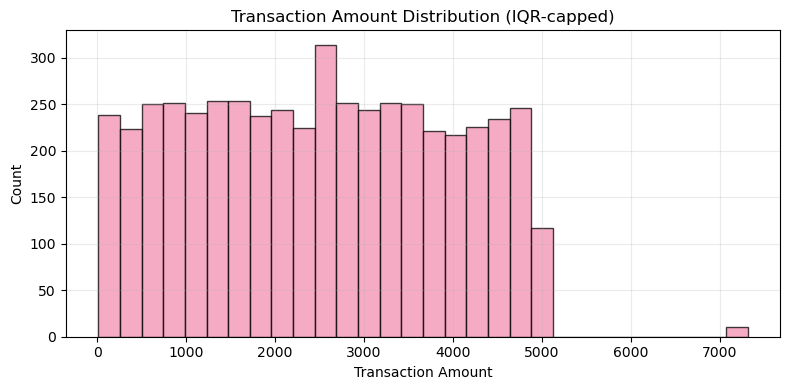

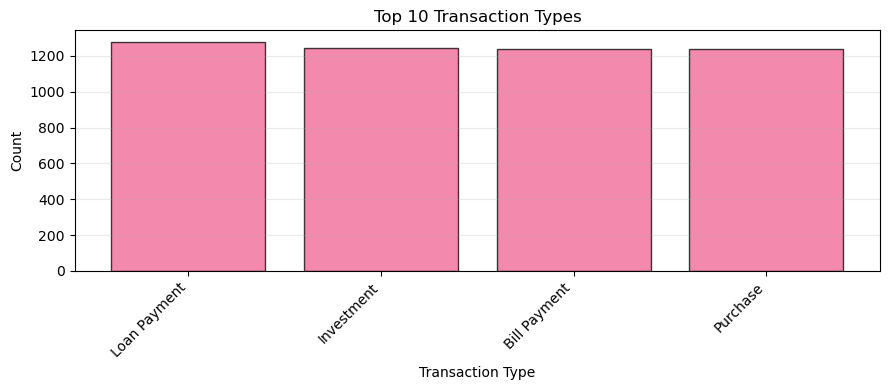


10.2 Customer Spending Behavior (Distributions)
--------------------------------------------------------------------------------


,total_spend,avg_spend,txn_count
count,993.00,993.00,993.00
mean,"12,569.72","2,497.78",5.04
std,"6,424.66",758.16,2.19
min,286.00,286.00,1.00
25%,"7,777.00","2,015.00",3.00
50%,"11,939.00","2,458.67",5.00
75%,"16,531.00","2,930.75",6.00
max,"37,281.00","4,993.00",13.00


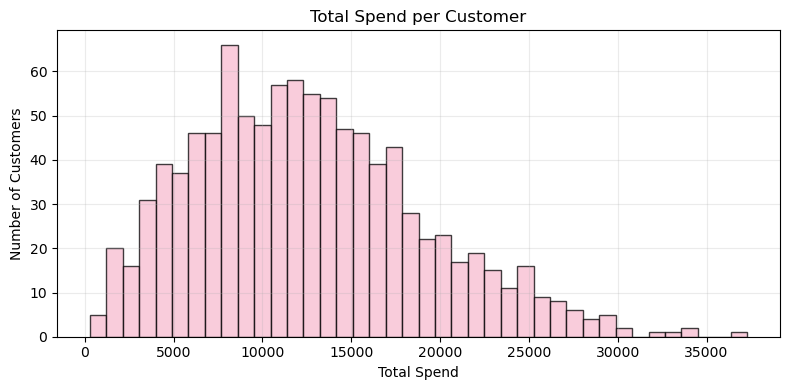

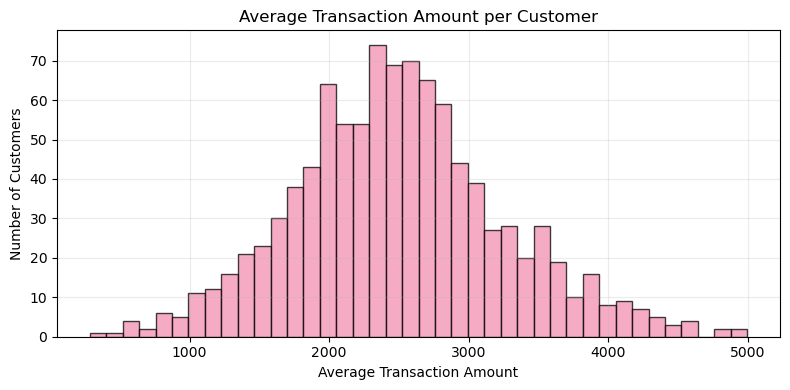

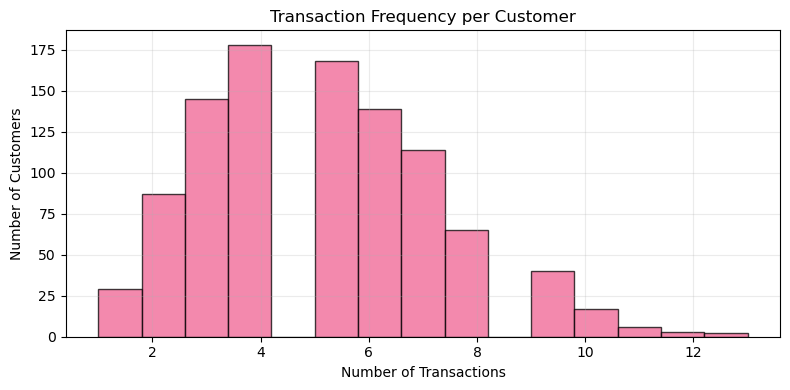


Key observations (spending behavior):
- Total spend ranges from 286.00 to 37281.00.
- Mean total spend is 12569.72 (Std: 6424.66).
- Distribution skew indicates a smaller segment of higher spenders.

10.3 Income Group Analysis (Percentile-based tiers)
--------------------------------------------------------------------------------
Income Group Distribution:
- Low: 199 customers (20.0%)
- Medium: 545 customers (54.9%)
- High: 249 customers (25.1%)


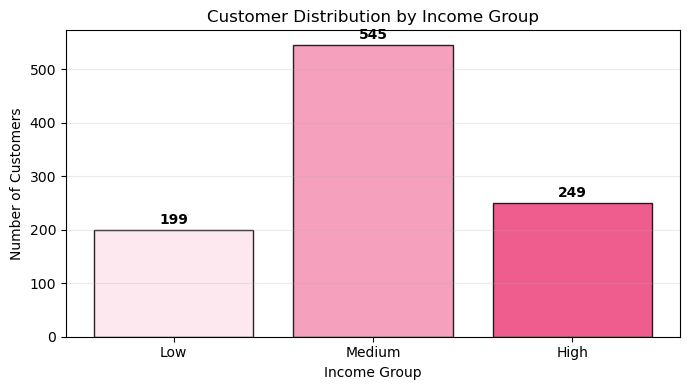

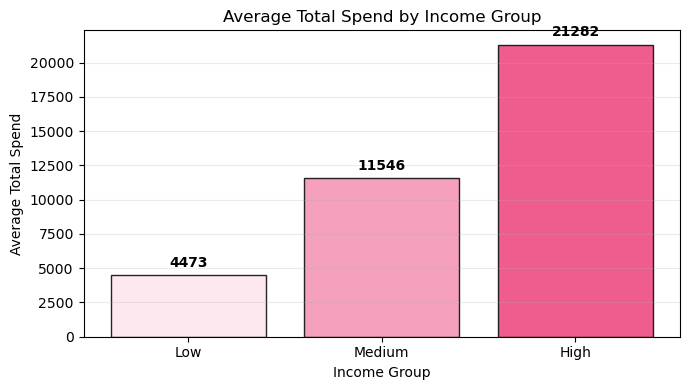

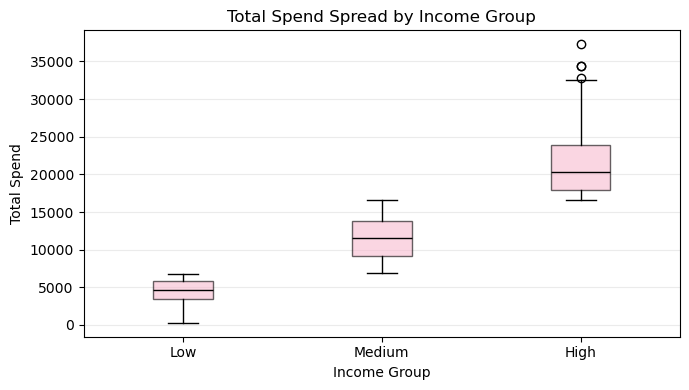

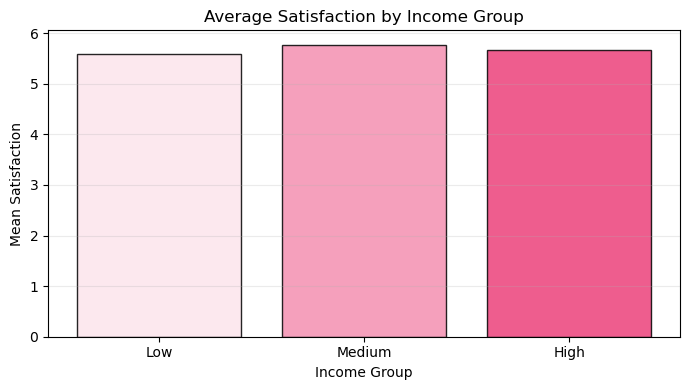


Key observations (income grouping):
- Percentile-based tiers are derived from customer total_spend (transaction-based proxy).
- Visual checks (averages + boxplot spread) confirm clear separation across income tiers.

10.4 Correlation Scan (Curated Customer Features)
--------------------------------------------------------------------------------


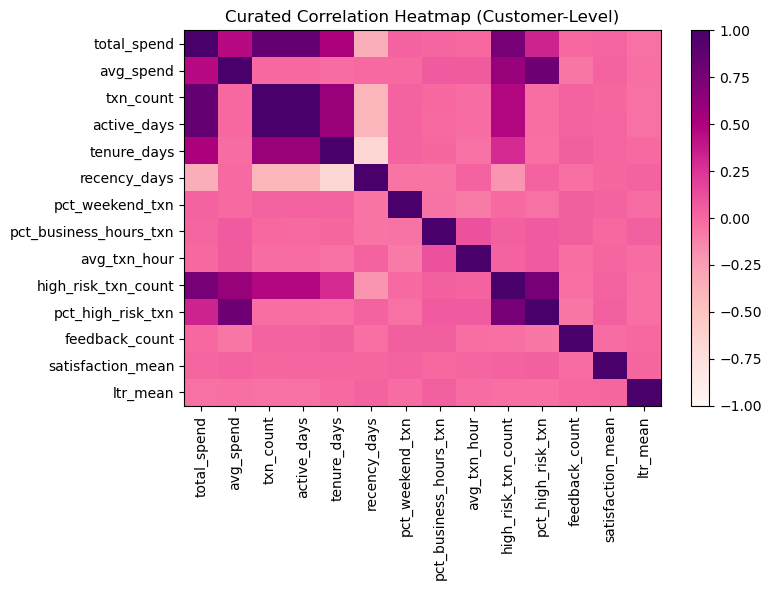


10.5 Satisfaction & Engagement Distribution Analysis
--------------------------------------------------------------------------------


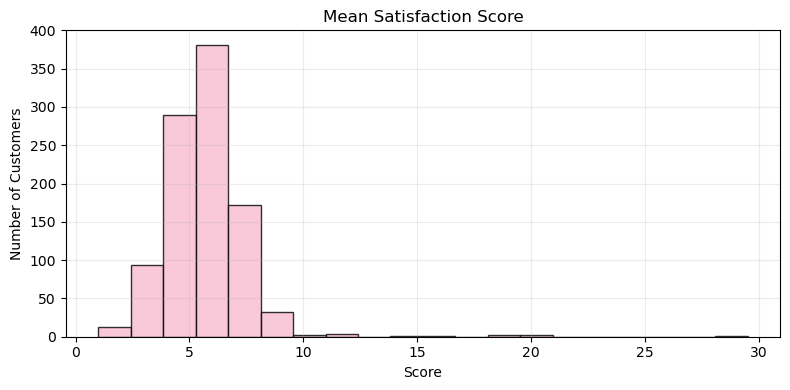

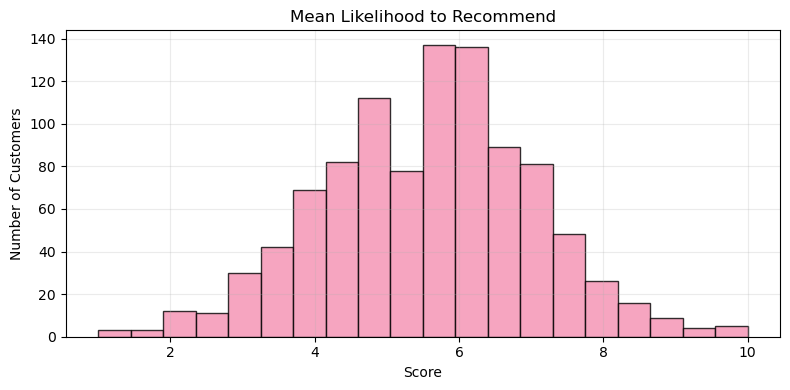

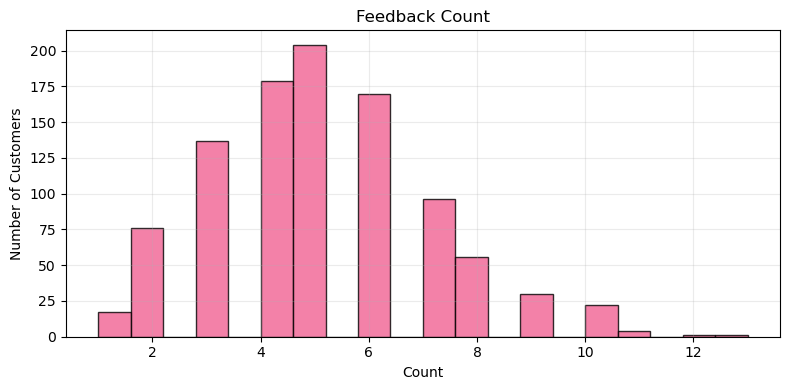

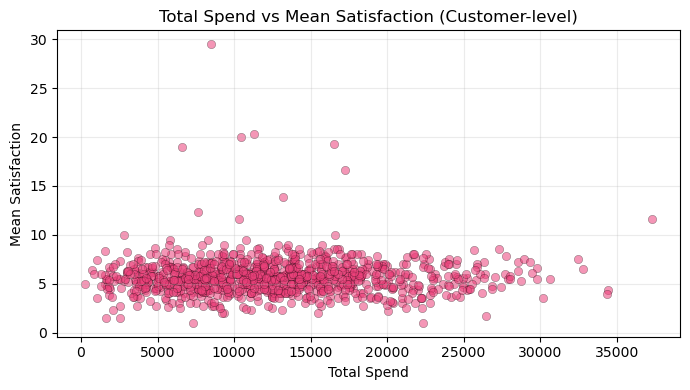

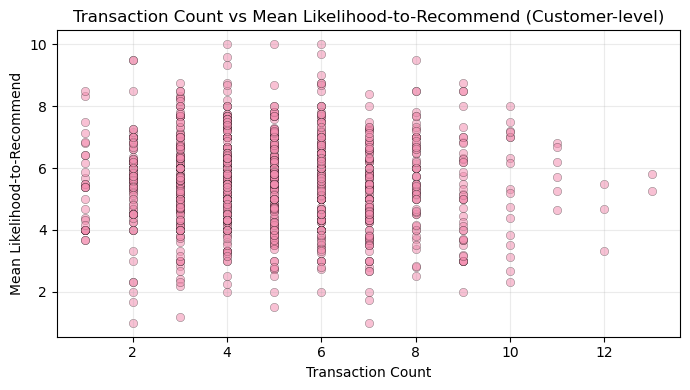


Key observations (satisfaction & engagement):
- Mean satisfaction: 5.71 (Std: 1.91).
- Mean LTR: 5.57 (Std: 1.47).
- Average feedback count: 5.05.
- Scatter plots provide a quick check for any spend/engagement relationship with feedback signals.


In [50]:
# EDA and visualizations (customer- and transaction-level views)
# Theme: shades of pink (soft gradient) to keep a consistent visual identity.

import numpy as np
import matplotlib.pyplot as plt

# Pink gradient palette (light -> dark)
pink_grad = ["#FCE4EC", "#F8BBD0", "#F48FB1", "#F06292", "#EC407A"]

print("\nEDA and VISUALIZATIONS")
print("-"*80)

# -------------------------------------------------------------------
# 10.1 Transaction-level overview (amount + type)
# -------------------------------------------------------------------
print("\n10.1 Transaction-Level Overview")
print("-"*80)

plt.figure(figsize=(8,4))
plt.hist(df["Transaction_Amount"].dropna(), bins=30, color=pink_grad[2], edgecolor="black", alpha=0.75)
plt.title("Transaction Amount Distribution (IQR-capped)")
plt.xlabel("Transaction Amount")
plt.ylabel("Count")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

top_types = df["Transaction_Type"].value_counts().head(10)
plt.figure(figsize=(9,4))
plt.bar(top_types.index.astype(str), top_types.values, color=pink_grad[3], edgecolor="black", alpha=0.75)
plt.title("Top 10 Transaction Types")
plt.xlabel("Transaction Type")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.grid(alpha=0.25, axis="y")
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------
# 10.2 Customer spending behavior (distributions)
# -------------------------------------------------------------------
print("\n10.2 Customer Spending Behavior (Distributions)")
print("-"*80)

spending_cols = ["total_spend", "avg_spend", "txn_count"]
display(customer_features[spending_cols].describe().round(2))

plt.figure(figsize=(8,4))
plt.hist(customer_features["total_spend"].dropna(), bins=40, color=pink_grad[1], edgecolor="black", alpha=0.75)
plt.title("Total Spend per Customer")
plt.xlabel("Total Spend")
plt.ylabel("Number of Customers")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,4))
plt.hist(customer_features["avg_spend"].dropna(), bins=40, color=pink_grad[2], edgecolor="black", alpha=0.75)
plt.title("Average Transaction Amount per Customer")
plt.xlabel("Average Transaction Amount")
plt.ylabel("Number of Customers")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,4))
plt.hist(customer_features["txn_count"].dropna(), bins=15, color=pink_grad[3], edgecolor="black", alpha=0.75)
plt.title("Transaction Frequency per Customer")
plt.xlabel("Number of Transactions")
plt.ylabel("Number of Customers")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("\nKey observations (spending behavior):")
print(f"- Total spend ranges from {customer_features['total_spend'].min():.2f} to {customer_features['total_spend'].max():.2f}.")
print(f"- Mean total spend is {customer_features['total_spend'].mean():.2f} (Std: {customer_features['total_spend'].std():.2f}).")
print("- Distribution skew indicates a smaller segment of higher spenders.")

# -------------------------------------------------------------------
# 10.3 Income group analysis (percentile-based tiers)
# -------------------------------------------------------------------
print("\n10.3 Income Group Analysis (Percentile-based tiers)")
print("-"*80)

income_order = ["Low", "Medium", "High"]
income_counts = customer_features["Income_Group"].value_counts().reindex(income_order).fillna(0).astype(int)
income_pct = (income_counts / income_counts.sum() * 100).round(1)

print("Income Group Distribution:")
for grp in income_order:
    print(f"- {grp}: {income_counts[grp]} customers ({income_pct[grp]}%)")

# Colors: Low lightest, Medium mid, High darkest
grp_colors = [pink_grad[0], pink_grad[2], pink_grad[4]]

plt.figure(figsize=(7,4))
bars = plt.bar(income_order, income_counts.values, color=grp_colors, edgecolor="black", alpha=0.85)
plt.title("Customer Distribution by Income Group")
plt.xlabel("Income Group")
plt.ylabel("Number of Customers")
plt.grid(alpha=0.25, axis="y")
for b in bars:
    plt.text(b.get_x() + b.get_width()/2, b.get_height() + max(income_counts.values)*0.01,
             f"{int(b.get_height())}", ha="center", va="bottom", fontweight="bold")
plt.tight_layout()
plt.show()

avg_spend_by_group = customer_features.groupby("Income_Group")["total_spend"].mean().reindex(income_order)

plt.figure(figsize=(7,4))
bars2 = plt.bar(income_order, avg_spend_by_group.values, color=grp_colors, edgecolor="black", alpha=0.85)
plt.title("Average Total Spend by Income Group")
plt.xlabel("Income Group")
plt.ylabel("Average Total Spend")
plt.grid(alpha=0.25, axis="y")
for i, v in enumerate(avg_spend_by_group.values):
    plt.text(i, v + (avg_spend_by_group.max()*0.02), f"{v:.0f}", ha="center", va="bottom", fontweight="bold")
plt.tight_layout()
plt.show()

# Add a "segmentation check": boxplot to show spread differences across groups (helps it look more meaningfully segmented)
plt.figure(figsize=(7,4))
data_bp = [customer_features.loc[customer_features["Income_Group"]==g, "total_spend"].dropna() for g in income_order]
plt.boxplot(data_bp, labels=income_order, patch_artist=True,
            boxprops=dict(facecolor=pink_grad[1], alpha=0.6),
            medianprops=dict(color="black"),
            whiskerprops=dict(color="black"),
            capprops=dict(color="black"))
plt.title("Total Spend Spread by Income Group")
plt.xlabel("Income Group")
plt.ylabel("Total Spend")
plt.grid(alpha=0.25, axis="y")
plt.tight_layout()
plt.show()

# Optional: Satisfaction by income group (if satisfaction_mean exists)
if "satisfaction_mean" in customer_features.columns:
    sat_by_group = customer_features.groupby("Income_Group")["satisfaction_mean"].mean().reindex(income_order)

    plt.figure(figsize=(7,4))
    plt.bar(income_order, sat_by_group.values, color=grp_colors, edgecolor="black", alpha=0.85)
    plt.title("Average Satisfaction by Income Group")
    plt.xlabel("Income Group")
    plt.ylabel("Mean Satisfaction")
    plt.grid(alpha=0.25, axis="y")
    plt.tight_layout()
    plt.show()

print("\nKey observations (income grouping):")
print("- Percentile-based tiers are derived from customer total_spend (transaction-based proxy).")
print("- Visual checks (averages + boxplot spread) confirm clear separation across income tiers.")

# -------------------------------------------------------------------
# 10.4 Correlation scan (curated subset for readability)
# -------------------------------------------------------------------
print("\n10.4 Correlation Scan (Curated Customer Features)")
print("-"*80)

# A curated set keeps the heatmap readable and focuses on the most decision-relevant signals.
candidate_cols = [
    "total_spend","avg_spend","txn_count","active_days","tenure_days","recency_days",
    "pct_weekend_txn","pct_business_hours_txn","avg_txn_hour",
    "high_risk_txn_count","pct_high_risk_txn",
    "feedback_count","satisfaction_mean","ltr_mean"
]

numeric = customer_features.select_dtypes(include=[np.number])
keep = [c for c in candidate_cols if c in numeric.columns]

if len(keep) >= 2:
    corr = numeric[keep].corr(numeric_only=True)
    plt.figure(figsize=(8,6))
    plt.imshow(corr, aspect="auto", cmap="RdPu", vmin=-1, vmax=1)
    plt.title("Curated Correlation Heatmap (Customer-Level)")
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
    plt.yticks(range(len(corr.columns)), corr.columns)
    plt.colorbar()
    plt.tight_layout()
    plt.show()
else:
    print("Not enough curated numeric columns for correlation heatmap.")

# -------------------------------------------------------------------
# 10.5 Satisfaction & Engagement Distribution Analysis
# -------------------------------------------------------------------
print("\n10.5 Satisfaction & Engagement Distribution Analysis")
print("-"*80)

# Distribution plots (if feedback features exist)
has_sat = "satisfaction_mean" in customer_features.columns
has_ltr = "ltr_mean" in customer_features.columns
has_fb  = "feedback_count" in customer_features.columns

if has_sat or has_ltr or has_fb:
    if has_sat:
        plt.figure(figsize=(8,4))
        plt.hist(customer_features["satisfaction_mean"].dropna(), bins=20, color=pink_grad[1], edgecolor="black", alpha=0.80)
        plt.title("Mean Satisfaction Score")
        plt.xlabel("Score")
        plt.ylabel("Number of Customers")
        plt.grid(alpha=0.25)
        plt.tight_layout()
        plt.show()

    if has_ltr:
        plt.figure(figsize=(8,4))
        plt.hist(customer_features["ltr_mean"].dropna(), bins=20, color=pink_grad[2], edgecolor="black", alpha=0.80)
        plt.title("Mean Likelihood to Recommend")
        plt.xlabel("Score")
        plt.ylabel("Number of Customers")
        plt.grid(alpha=0.25)
        plt.tight_layout()
        plt.show()

    if has_fb:
        plt.figure(figsize=(8,4))
        plt.hist(customer_features["feedback_count"].dropna(), bins=20, color=pink_grad[3], edgecolor="black", alpha=0.80)
        plt.title("Feedback Count")
        plt.xlabel("Count")
        plt.ylabel("Number of Customers")
        plt.grid(alpha=0.25)
        plt.tight_layout()
        plt.show()


# Relationship plots (kept because they connect spend/engagement to satisfaction signals)
if has_sat:
    plt.figure(figsize=(7,4))
    plt.scatter(customer_features["total_spend"], customer_features["satisfaction_mean"],
                alpha=0.55, edgecolor="black", linewidth=0.3, color=pink_grad[4])
    plt.title("Total Spend vs Mean Satisfaction (Customer-level)")
    plt.xlabel("Total Spend")
    plt.ylabel("Mean Satisfaction")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

if has_ltr:
    plt.figure(figsize=(7,4))
    plt.scatter(customer_features["txn_count"], customer_features["ltr_mean"],
                alpha=0.55, edgecolor="black", linewidth=0.3, color=pink_grad[2])
    plt.title("Transaction Count vs Mean Likelihood-to-Recommend (Customer-level)")
    plt.xlabel("Transaction Count")
    plt.ylabel("Mean Likelihood-to-Recommend")
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

print("\nKey observations (satisfaction & engagement):")
if has_sat:
    print(f"- Mean satisfaction: {customer_features['satisfaction_mean'].mean():.2f} (Std: {customer_features['satisfaction_mean'].std():.2f}).")
if has_ltr:
    print(f"- Mean LTR: {customer_features['ltr_mean'].mean():.2f} (Std: {customer_features['ltr_mean'].std():.2f}).")
if has_fb:
    print(f"- Average feedback count: {customer_features['feedback_count'].mean():.2f}.")
print("- Scatter plots provide a quick check for any spend/engagement relationship with feedback signals.")

## Feature Dictionary (documentation)

This section defines a short “feature dictionary” describing the main engineered variables.
The goal is to make the engineered dataset easier to interpret and to clearly document how key features were constructed.


In [51]:
# Build a compact feature dictionary for the engineered customer-level table.
# This table is exported to features/feature_dictionary.csv

feature_rows = [
    {"feature": "total_spend", "group": "Spending", "description": "Sum of all transaction amounts per customer (used as spend-based income proxy)."},
    {"feature": "avg_spend", "group": "Spending", "description": "Average transaction amount per customer."},
    {"feature": "txn_count", "group": "Engagement", "description": "Number of transactions recorded for the customer."},
    {"feature": "active_days", "group": "Engagement", "description": "Number of distinct transaction days for the customer."},
    {"feature": "tenure_days", "group": "Temporal", "description": "Days between first and last observed transaction."},
    {"feature": "recency_days", "group": "Temporal", "description": "Days since the most recent observed transaction (relative to dataset maximum date)."},
    {"feature": "pct_weekend_txn", "group": "Temporal", "description": "Share of transactions that occur on weekends."},
    {"feature": "pct_business_hours_txn", "group": "Temporal", "description": "Share of transactions that occur during business hours (09:00–16:59)."},
    {"feature": "avg_txn_hour", "group": "Temporal", "description": "Average transaction hour (0–23)."},
    {"feature": "Income_Group", "group": "IncomeProxy", "description": "Low/Medium/High derived from percentile-based tiers of customer total_spend (transaction-based proxy)."},
    {"feature": "feedback_count", "group": "Feedback", "description": "Number of feedback entries recorded for the customer."},
    {"feature": "satisfaction_mean", "group": "Feedback", "description": "Average satisfaction score per customer (from feedback records)."},
    {"feature": "ltr_mean", "group": "Feedback", "description": "Average likelihood-to-recommend per customer (from feedback records)."},
    {"feature": "pct_high_risk_txn", "group": "RiskProxy", "description": "Share of transactions classified as high-amount (>= 75th percentile of Transaction_Amount)."},
    {"feature": "high_risk_txn_count", "group": "RiskProxy", "description": "Count of high-amount transactions (>= 75th percentile of Transaction_Amount)."},
]

# Add dynamic entries for transaction-type count features and time-of-day proportions if present
for col in customer_features.columns:
    if col.startswith("count_type_"):
        feature_rows.append({
            "feature": col,
            "group": "TransactionMix",
            "description": "Count of transactions for this transaction type (per customer)."
        })
    if col.startswith("pct_tod_"):
        feature_rows.append({
            "feature": col,
            "group": "TimeOfDay",
            "description": "Proportion of transactions occurring in this time-of-day bucket (per customer)."
        })

feature_dictionary = pd.DataFrame(feature_rows).drop_duplicates(subset=["feature"]).reset_index(drop=True)
display(feature_dictionary.head(15))
print("Feature dictionary rows:", feature_dictionary.shape[0])


,feature,group,description
0,total_spend,Spending,Sum of all transaction amounts per customer (u...
1,avg_spend,Spending,Average transaction amount per customer.
2,txn_count,Engagement,Number of transactions recorded for the customer.
3,active_days,Engagement,Number of distinct transaction days for the cu...
4,tenure_days,Temporal,Days between first and last observed transaction.
5,recency_days,Temporal,Days since the most recent observed transactio...
6,pct_weekend_txn,Temporal,Share of transactions that occur on weekends.
7,pct_business_hours_txn,Temporal,Share of transactions that occur during busine...
8,avg_txn_hour,Temporal,Average transaction hour (0–23).
9,Income_Group,IncomeProxy,Low/Medium/High derived from percentile-based ...


Feature dictionary rows: 23


## 11) Exports

### Cleaned outputs (`cleaned/`)
- `merged_master_transactions.csv` (merged + cleaned + engineered columns)
- `products_cleaned.csv`
- `feedback_customer_summary.csv`

### Engineered outputs (`features/`)
- `customer_features.csv` (one row per customer)
- `customer_features_scaled.csv`
- `feature_dictionary.csv`


In [52]:
cleaned_dir = Path("cleaned")
features_dir = Path("features")
cleaned_dir.mkdir(exist_ok=True)
features_dir.mkdir(exist_ok=True)


# Ensure clean ordering for exported tables (prevents lexicographic-looking IDs like 1, 10, 100)
for _name, _df in {
    "feedback_customer_summary": feedback_customer_summary,
    "customer_features": customer_features,
    "customer_features_scaled": customer_features_scaled,
}.items():
    if isinstance(_df, pd.DataFrame) and "Customer_ID" in _df.columns:
        _df["Customer_ID"] = pd.to_numeric(_df["Customer_ID"], errors="coerce").astype("Int64")
        _df.sort_values("Customer_ID", inplace=True)
        _df.reset_index(drop=True, inplace=True)

# Cleaned exports
df.to_csv(cleaned_dir / "merged_master_transactions.csv", index=False)
products.to_csv(cleaned_dir / "products_cleaned.csv", index=False)
feedback_customer_summary.to_csv(cleaned_dir / "feedback_customer_summary.csv", index=False)

# Feature exports
customer_features.to_csv(features_dir / "customer_features.csv", index=False)
customer_features_scaled.to_csv(features_dir / "customer_features_scaled.csv", index=False)
feature_dictionary.to_csv(features_dir / "feature_dictionary.csv", index=False)

print("Saved cleaned:")
print("-", cleaned_dir / "merged_master_transactions.csv")
print("-", cleaned_dir / "products_cleaned.csv")
print("-", cleaned_dir / "feedback_customer_summary.csv")
print("Saved features:")
print("-", features_dir / "customer_features.csv")
print("-", features_dir / "customer_features_scaled.csv")
print("-", features_dir / "feature_dictionary.csv")


Saved cleaned:
- cleaned/merged_master_transactions.csv
- cleaned/products_cleaned.csv
- cleaned/feedback_customer_summary.csv
Saved features:
- features/customer_features.csv
- features/customer_features_scaled.csv
- features/feature_dictionary.csv


## 12) Summary, Conclusion, and Key Insights

### Key insights (from EDA + engineered features)

#### A) Spending behavior
- Customer total spend ranges from **286.00** to **37,281.00**.  
- Average total spend is **12,569.72**, with a standard deviation of **6,424.66**, indicating meaningful variability across customers.  
- The distribution is **right-skewed** (a smaller segment accounts for disproportionately higher spend), supporting segmentation.

#### B) Income group segmentation (percentile-based tiers: 20/55/25)
Income tiers were created using transaction-derived total spend cutoffs:
- **Low**: ≤ **P20**
- **Medium**: **P20** to **P75**
- **High**: ≥ **P75**

Group distribution:
- **Low**: **199** customers (**20.0%**)
- **Medium**: **545** customers (**54.9%**)
- **High**: **249** customers (**25.1%**)

Spend separation check (mean total spend by tier):
- **Low**: **4,473**
- **Medium**: **11,546**
- **High**: **21,282**

**Interpretation:** The tiering creates clear spend stratification, providing a practical income proxy for segmentation and downstream modeling.

#### C) Satisfaction & engagement signals
Overall feedback-driven metrics:
- Mean satisfaction: **5.71** (Std: **1.91**)
- Mean likelihood-to-recommend: **5.57** (Std: **1.47**)
- Average feedback count per customer: **5.05**

Relationship checks:
- **Total spend vs mean satisfaction** helps validate whether spend relates to customer experience signals.
- **Transaction count vs likelihood-to-recommend** helps validate whether higher engagement aligns with advocacy.
